In [38]:
import matplotlib.pyplot as plt
import pandas as pd
import os
import numpy as np
import seaborn as sns

In [2]:

def calculate_progress(data):
    chunks = 10
    chunk_size = data["epoch"].max() / chunks
    if chunk_size < 1:
        chunk_size = 1
        chunks = int(data["epoch"].max())
    # print(chunk_size)
    # print('data["epoch"].max()', data["epoch"].max())
    new_col = [np.nan for i in range(len(data["step"]))]
    data["percentage"] = new_col
    # Create a new column "new step" with values at 10% intervals
    for i in range(1, chunks+1):
        
        epoch = int(i * chunk_size)
        # print("epoch:", epoch)
        data.loc[data["epoch"] == epoch, "percentage"] = 1/chunks*i*100
        # print("progress:", 1/chunks*i*100)
    #adding start point
    data.at[0, "percentage"] = 0
    # print('data.loc[data["epoch"] == 4, "val_loss_epoch"]', data.loc[data["epoch"] == 4, "val_loss_epoch"].max())
    data.at[0, "val_loss_epoch"] = data.loc[data["epoch"] == 1, "val_loss_epoch"].max()
    data.at[0, "val binary_accuracy_epoch"] = data.loc[data["epoch"] == 1, "val binary_accuracy_epoch"].max()
    if data.loc[data["epoch"] == chunks, "val_loss_epoch"].isna().any():
        data.loc[data["epoch"] == chunks, "val_loss_epoch"] = data.loc[data["epoch"] == chunks-1, "val_loss_epoch"].max()
        data.loc[data["epoch"] == chunks, "val binary_accuracy_epoch"] = data.loc[data["epoch"] == chunks-1, "val binary_accuracy_epoch"].max()
    min_val_loss = data.loc[:, "val_loss_epoch"].min()
    start_val_loss = data.loc[data["epoch"] == 1, "val_loss_epoch"].max()
    max_val_acc = data.loc[:, "val binary_accuracy_epoch"].max()
    start_val_acc = data.loc[data["epoch"] == 1, "val binary_accuracy_epoch"].max()
    return data, start_val_loss, min_val_loss, start_val_acc, max_val_acc



In [46]:
def plot_by_progress(data, marker, cond, layer, ax, down):
    
    # Set seaborn style
    sns.set(style="white")
    # Plot validation loss on the left y-axis
    sns.lineplot(x="percentage", y="val_loss_epoch", data=data, marker=marker, markersize = 10, color="b", ax=ax)
    ax.set_xlabel("Training Progress (%)")
    ax.set_ylabel("Loss")
    ax.tick_params(axis="y", labelcolor="b")

    # Create a second y-axis for validation accuracy
    ax2 = ax.twinx()
    sns.lineplot(x="percentage", y="val binary_accuracy_epoch", data=data, marker=marker, markersize = 10, color="g", ax=ax2)
    ax2.set_ylabel("Performance")
    ax2.tick_params(axis="y", labelcolor="g")
    if layer == 1:
    # Add legend with modified color
        ax2.legend([cond], frameon=False, fontsize=15, labelcolor="black", bbox_to_anchor=(-0.15, 1-down))
    ax2.set_ylim(0.5,0.9)
    ax.set_ylim(0.25,1.4)
    # Set title
    plt.title(f"Layer-{layer} (Validation Loss and Accuracy vs. Progress)")

    # Print a success message
    print("Dual y-axis lineplot created and displayed.")
# def plot_by_layers():



def plot(layer_dict): 
    layer_df = {}
    # layer_acc = {}
    fig, axs = plt.subplots(3, 4, figsize=(50, 20))
    idx = 0
    for i in range(12):
        layer = i+1
        row, col = divmod(i, 4)
        ax = axs[row, col]
        if layer in layer_dict.keys():
            conditions = {"reinit": "o", "transfer": "v", "samedist": "^", "one hot": "*"}
            for (cond, marker), down in zip(conditions.items(), [0, 0.05, 0.1, 0.15]):

                data_path = layer_dict[layer][cond]
                data = pd.read_table(data_path, sep= ",")
                idx += 1
                #calculate the progress 0-100%
                data, start_val_loss, min_val_loss, start_val_acc, max_val_acc = calculate_progress(data)
                layer_df.setdefault("start_val_loss", []).append(start_val_loss)
                layer_df.setdefault("layers", []).append(layer)
                layer_df.setdefault("conditions", []).append(cond)
                layer_df.setdefault("min_val_loss", []).append(min_val_loss)
                layer_df.setdefault("start_val_acc", []).append(start_val_acc)
                layer_df.setdefault("max_val_acc", []).append(max_val_acc)

                layer_df.setdefault("delta_loss", []).append(min_val_loss-start_val_loss)
                layer_df.setdefault("delta_acc", []).append(max_val_acc-start_val_acc)

                layer_df.setdefault("index", []).append(idx)
                layer_df.setdefault("colors", []).append("black")
                layer_df.setdefault("labels", []).append(str(layer)+"_"+cond)
               
                # plot_by_progress(data, marker, cond, layer, ax, down)
    layer_df = pd.DataFrame(layer_df)

    # Group by 'layers' and find the row with the maximum 'start_val_acc'
    max_acc_row = layer_df.groupby('layers')['max_val_acc'].idxmax()
    min_loss_row = layer_df.groupby('layers')['min_val_loss'].idxmin()
    second_max_acc_row = layer_df.groupby('layers')['max_val_acc'].nlargest(2).reset_index(level=0).groupby('layers')['max_val_acc'].idxmin()
    second_min_loss_row = layer_df.groupby('layers')['min_val_loss'].nsmallest(2).reset_index(level=0).groupby('layers')['min_val_loss'].idxmax()


    layer_df['markers'] = layer_df['conditions'].apply(lambda x: 'o' if x == 'reinit' else ('v' if x == 'transfer' else ('^' if x == 'samedist' else "*")))

    # Create a new column 'max_condition' with the corresponding 'conditions' value
    layer_df['maxacc_condition'] = layer_df.loc[max_acc_row, 'conditions']
    layer_df['maxacc_value'] = layer_df.loc[max_acc_row, 'max_val_acc']
    layer_df['second_max_acc_condition'] = layer_df.loc[second_max_acc_row, 'conditions']
    layer_df['second_max_acc_value'] = layer_df.loc[second_max_acc_row, 'max_val_acc']
    layer_df['second_max_acc_marker'] = layer_df.loc[second_max_acc_row, 'markers']
    
    layer_df['minloss_condition'] = layer_df.loc[min_loss_row, 'conditions']
    layer_df['minloss_value'] = layer_df.loc[min_loss_row, 'min_val_loss']
    layer_df['second_min_loss_condition'] = layer_df.loc[second_min_loss_row, 'conditions']
    layer_df['second_min_loss_value'] = layer_df.loc[second_min_loss_row, 'min_val_loss']
    layer_df['second_min_loss_marker'] = layer_df.loc[second_min_loss_row, 'markers']

    # fig, axs = plt.subplots(1, 2, figsize=(10, 20))
    print(layer_df)
    


               


    # Save the plot as an image (optional)
    output_dir = "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/Figure"
    os.makedirs(output_dir, exist_ok=True)  # Create the directory if it doesn't exist

    # Save the plot as an image
    output_path = os.path.join(output_dir, "lineplot.png")
    plt.savefig(output_path, dpi = 300)
    return layer_df
    # Show the plot
    # plt.show()





    start_val_loss  layers conditions  min_val_loss  start_val_acc  \
0         0.864874       1     reinit      0.661477       0.840364   
1         0.329383       1   transfer      0.324777       0.858985   
2         0.328956       1   samedist      0.325541       0.859107   
3         0.320492       1    one hot      0.313228       0.857684   
4         1.139305       2     reinit      0.627529       0.829065   
5         0.337783       2   transfer      0.314180       0.852983   
6         0.340105       2   samedist      0.315724       0.847776   
7         0.320492       2    one hot      0.313228       0.857684   
8         1.084387       3     reinit      0.644056       0.820709   
9         0.345974       3   transfer      0.316933       0.858010   
10        0.337239       3   samedist      0.315242       0.851894   
11        0.320492       3    one hot      0.313228       0.857684   
12        0.824568       4     reinit      0.618069       0.790433   
13        0.341028  

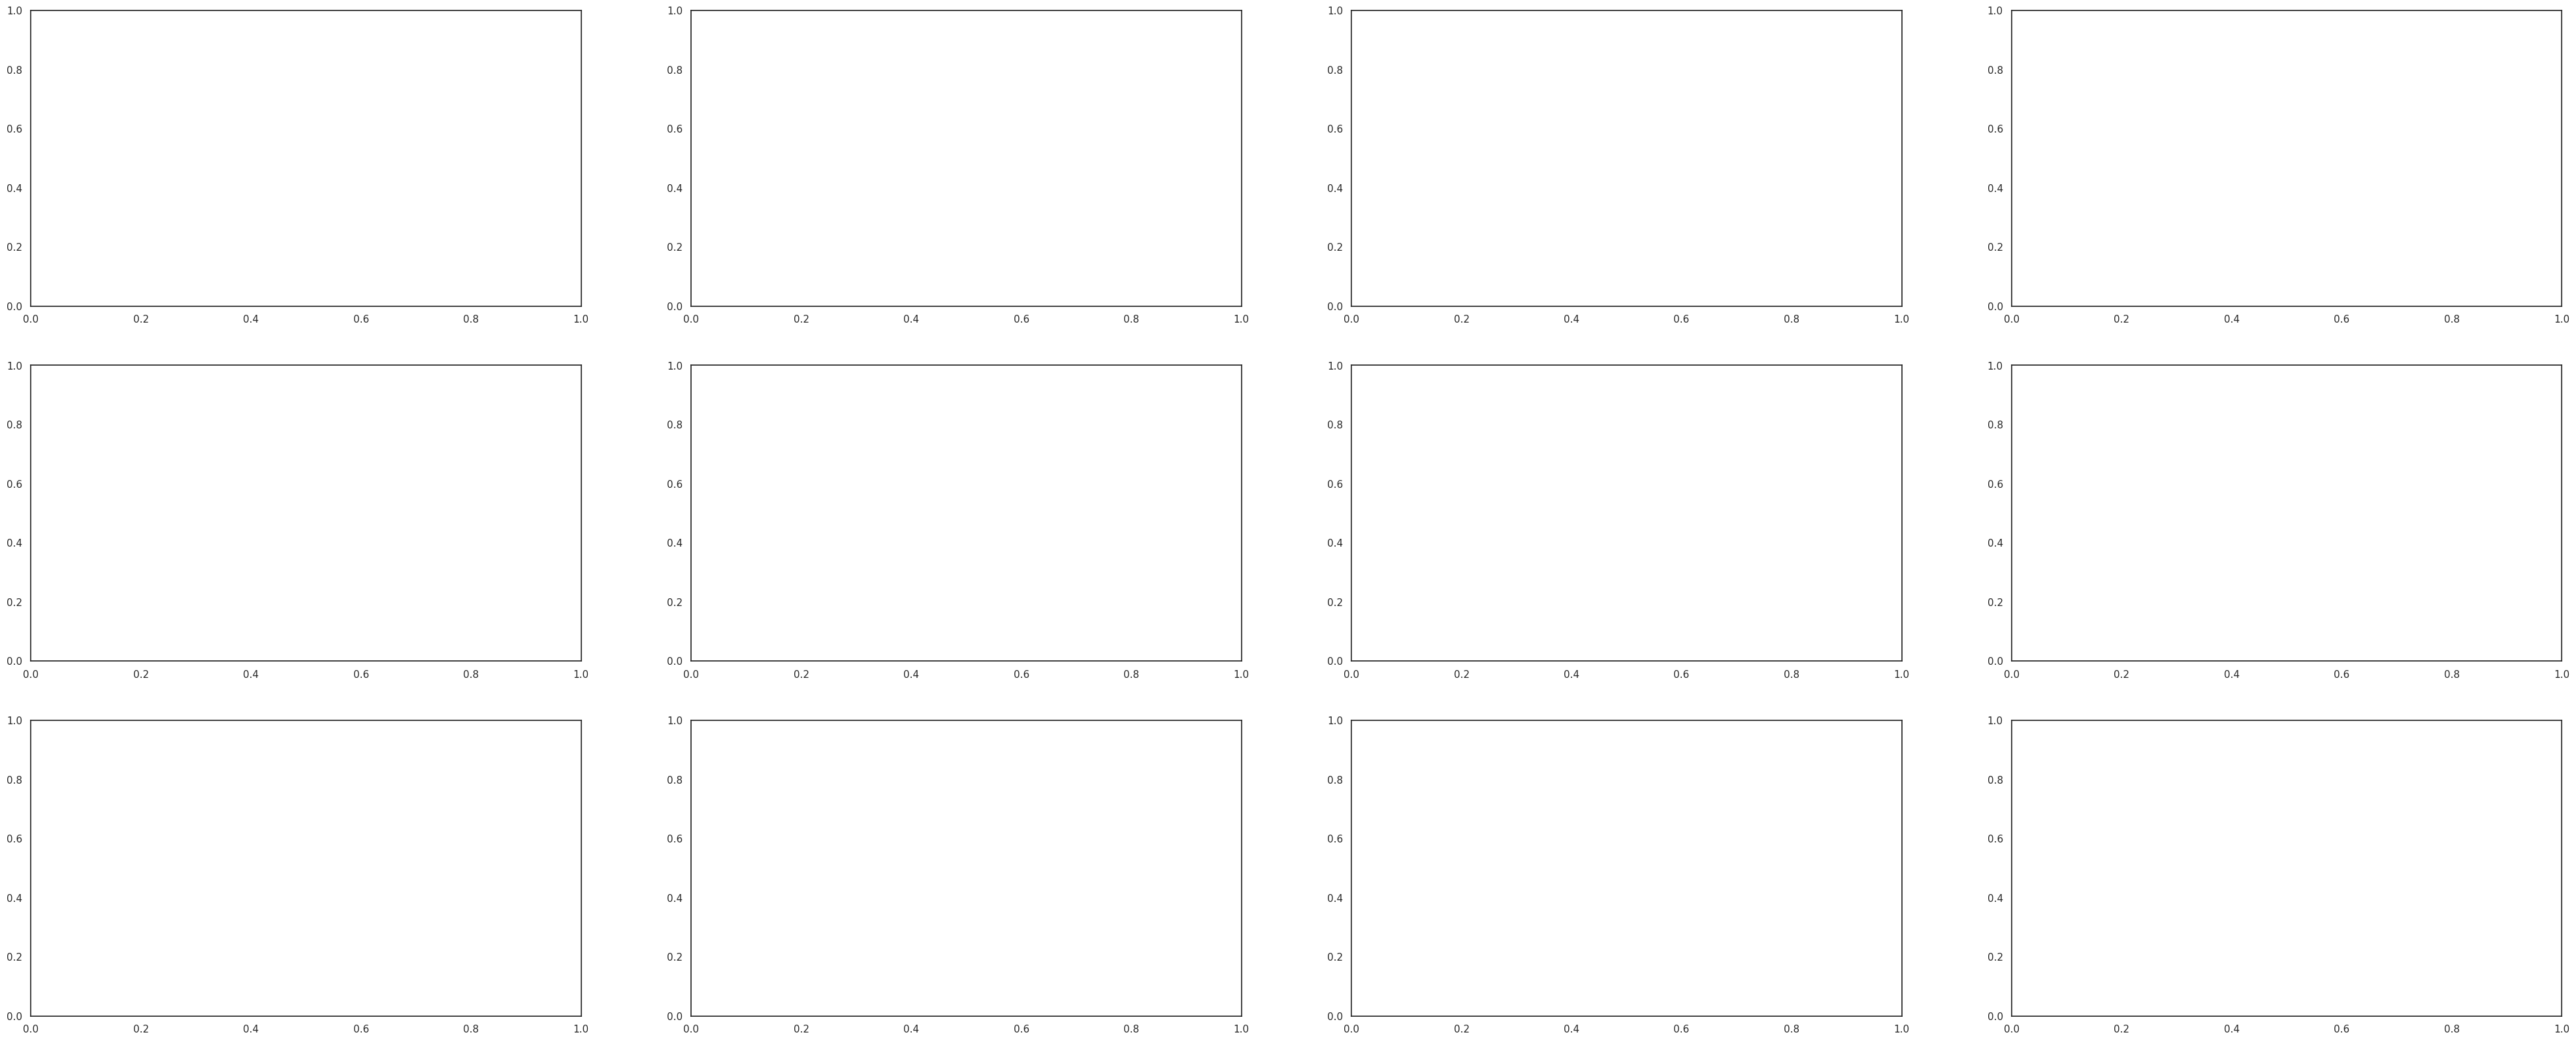

In [47]:
layer_dict = {1 : {"one hot": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_1_onehot/version_2/metrics.csv",
                   "reinit": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_1_reinit/version_5/metrics.csv",
                   "transfer": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_1_transfer/version_4/metrics.csv",
                   "samedist": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_1_samedist/version_3/metrics.csv"},
              2 : {"one hot": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_1_onehot/version_2/metrics.csv",
                  "reinit": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_2_reinit/version_7/metrics.csv",
                  "transfer": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_2_transfer/version_7/metrics.csv",
                  "samedist": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_2_samedist/version_6/metrics.csv"},
              3 : {"one hot": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_1_onehot/version_2/metrics.csv",
                   "reinit": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_3_reinit/version_3/metrics.csv",
                   "transfer": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_3_transfer/version_2/metrics.csv",
                   "samedist": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_3_samedist/version_2/metrics.csv"},
              4 : {"one hot": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_1_onehot/version_2/metrics.csv",
                   "reinit": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_4_reinit/version_4/metrics.csv",
                   "transfer": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_4_transfer/version_4/metrics.csv",
                   "samedist": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_4_samedist/version_3/metrics.csv"},
              5 : {"one hot": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_1_onehot/version_2/metrics.csv",
                   "reinit": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_5_reinit/version_3/metrics.csv",
                   "transfer": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_5_transfer/version_4/metrics.csv",
                   "samedist": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_5_samedist/version_4/metrics.csv"},
              6: {"one hot": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_1_onehot/version_2/metrics.csv",
                  "reinit": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_6_reinit/version_4/metrics.csv",
                  "transfer": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_6_transfer/version_4/metrics.csv",
                  "samedist": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_6_samedist/version_3/metrics.csv"},
              7: {"one hot": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_1_onehot/version_2/metrics.csv",
                  "reinit": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_7_reinit/version_2/metrics.csv",
                  "transfer": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_7_transfer/version_2/metrics.csv",
                  "samedist": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_7_samedist/version_1/metrics.csv"},
              8: {"one hot": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_1_onehot/version_2/metrics.csv",
                  "reinit": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_8_reinit/version_5/metrics.csv",
                  "transfer": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_8_transfer/version_4/metrics.csv",
                  "samedist": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_8_samedist/version_4/metrics.csv"},
              9: {"one hot": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_1_onehot/version_2/metrics.csv",
                  "reinit": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_9_reinit/version_3/metrics.csv",
                  "transfer": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_9_transfer/version_4/metrics.csv",
                  "samedist": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_9_samedist/version_3/metrics.csv"},
              10: {"one hot": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_1_onehot/version_2/metrics.csv",
                   "reinit": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_10_reinit/version_3/metrics.csv",
                   "transfer": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_10_transfer/version_3/metrics.csv",
                   "samedist": "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/parnet_10_samedist/version_4/metrics.csv"}
              }
              
layer_df = plot(layer_dict)

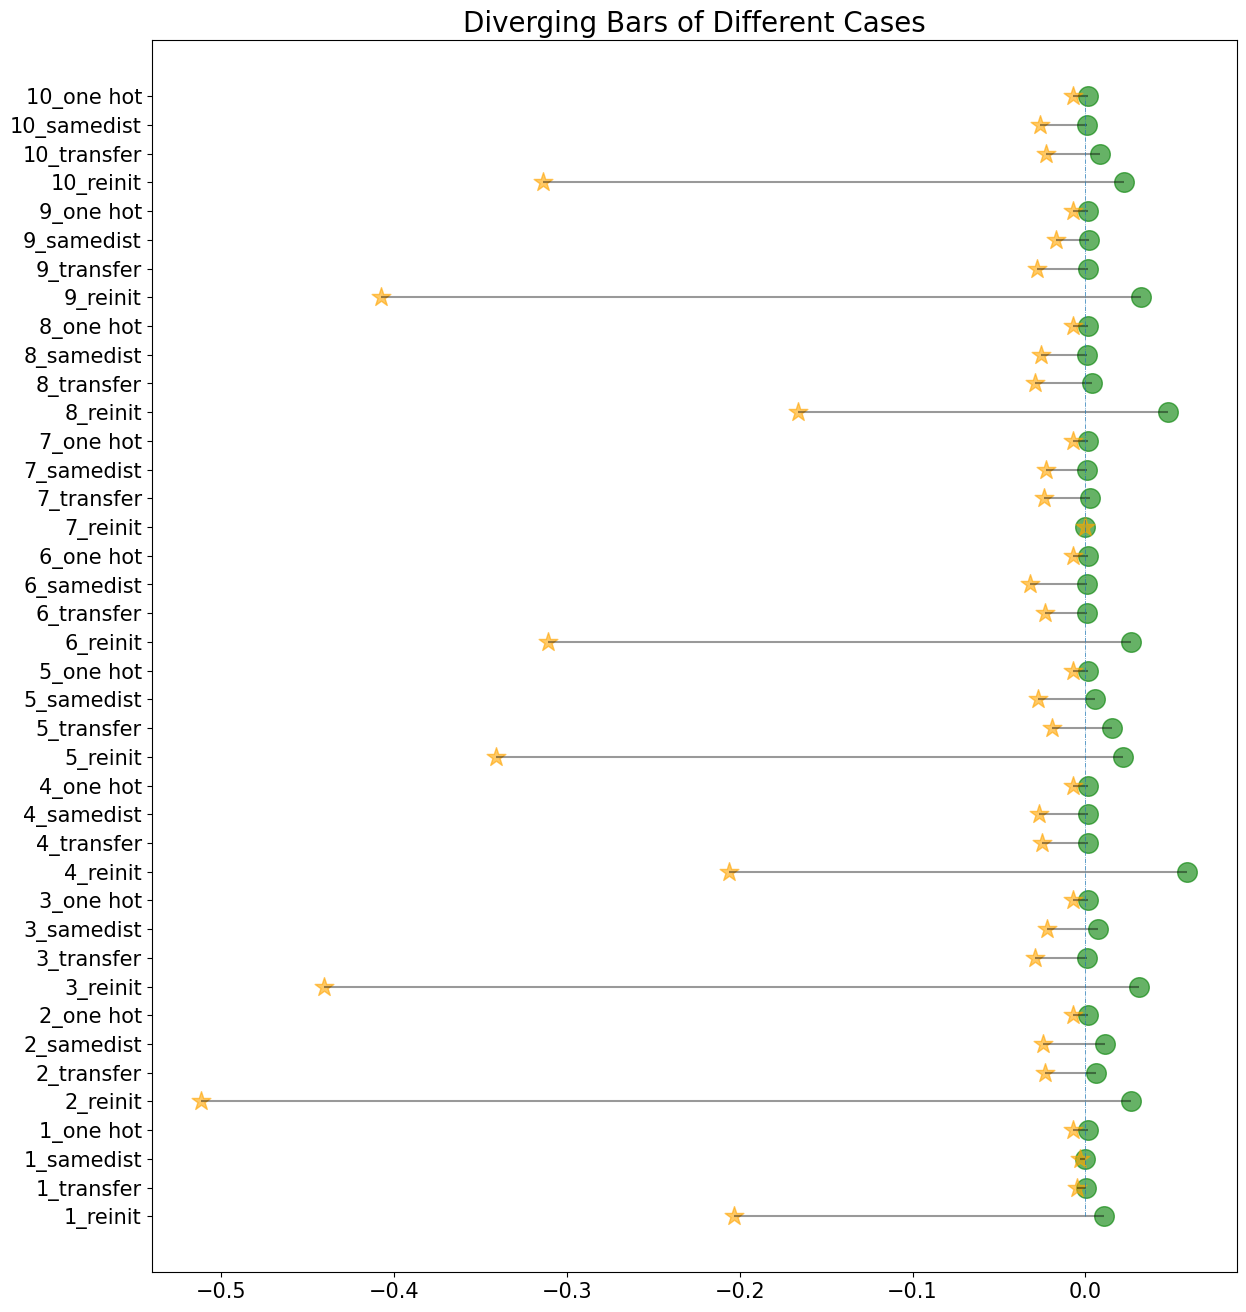

In [31]:
# Draw plot
import matplotlib.patches as patches
plt.figure(figsize=(14,16))
plt.hlines(y=layer_df.index, xmin=layer_df.delta_loss, xmax=layer_df.delta_acc, color=layer_df.colors, alpha=0.4, linewidth=1.5)
plt.vlines(x=0, ymin=0, ymax=layer_df.index.max(), linewidth=0.5, linestyles = "dashdot")

# plt.hlines(y=layer_df.index, xmin=0, xmax=layer_df.delta_loss, color=layer_df.colors, alpha=0.4, linewidth=1)
plt.scatter(layer_df.delta_acc, layer_df.index, color="green", alpha=0.6, marker="o", s=200)
plt.scatter(layer_df.delta_loss, layer_df.index, color="orange", alpha=0.6, marker="*", s=200)
plt.yticks(layer_df.index, layer_df.labels)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.title('Diverging Bars of Different Cases', fontdict={'size':20})
 # Save the plot as an image (optional)
output_dir = "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/Figure"
os.makedirs(output_dir, exist_ok=True)  # Create the directory if it doesn't exist

# Save the plot as an image
output_path = os.path.join(output_dir, "Diverging_bar.png")
plt.savefig(output_path, dpi = 300)

In [80]:
[k for k in layer_df["second_max_acc_value"] if len(str(k)) > 3]

[0.8591670989990234,
 0.8590390682220459,
 0.8590390682220459,
 0.8592206239700317,
 0.8590995669364929,
 0.8590390086174011,
 0.8590390682220459,
 0.8590390682220459,
 0.8590390086174011,
 0.8591601252555847]

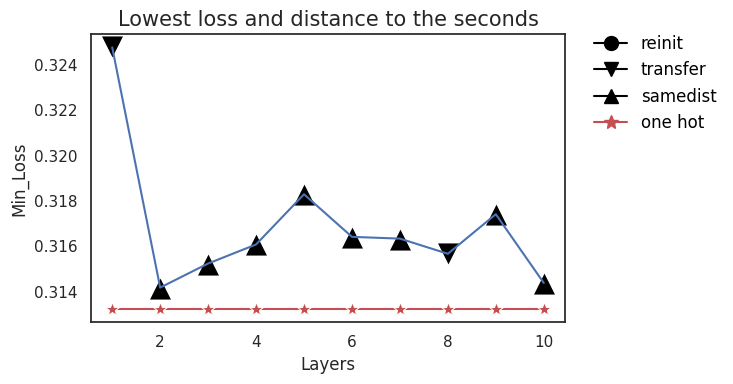

In [158]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Assuming layer_df and conditions are defined

# Create a figure and axis object
fig, axe = plt.subplots(figsize=(8, 4))

sns.set(style="white")

# Plot validation loss on the left y-axis
markers = [x for x in list(layer_df["second_max_acc_marker"]) if x is not np.nan]
sns.lineplot(x="layers", y="minloss_value", data=layer_df, marker="*", markersize=10, color="r", ax=axe)

conditions = {"reinit": "o", "transfer": "v", "samedist": "^", "one hot": "*"}
inversed_conditions = {value: key for key, value in conditions.items()}

for i in range(10):
    y = [k for k in layer_df["second_min_loss_value"] if len(str(k)) > 3][i]
    marker = markers[i]
    label = inversed_conditions[marker]
    sns.scatterplot(x=[i + 1], y=[y], color="black", marker=marker, s=300, ax=axe, label=label)

sns.lineplot(x="layers", y="second_min_loss_value", data=layer_df, color="b", ax=axe)

# Update legend
legend_handles = [plt.Line2D([0], [0], marker=marker, color='black', markersize=10, label=label) if label != "one hot" 
                  else plt.Line2D([0], [0], marker=marker, color='r', markersize=10, label=label)
                  for label, marker in conditions.items()]
plt.legend(handles=legend_handles, frameon=False, fontsize=12, labelcolor="black", bbox_to_anchor=(1.35, 1.05))

plt.ylabel("Min_Loss")
plt.xlabel("Layers")
plt.title("Lowest loss and distance to the seconds", fontdict={'size':15})
output_dir = "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/Figure"
os.makedirs(output_dir, exist_ok=True)  # Create the directory if it doesn't exist

# Save the plot as an image
output_path = os.path.join(output_dir, "Parnet_Layers_vs_loss.png")
plt.tight_layout()
plt.savefig(output_path, dpi = 300)
plt.show()


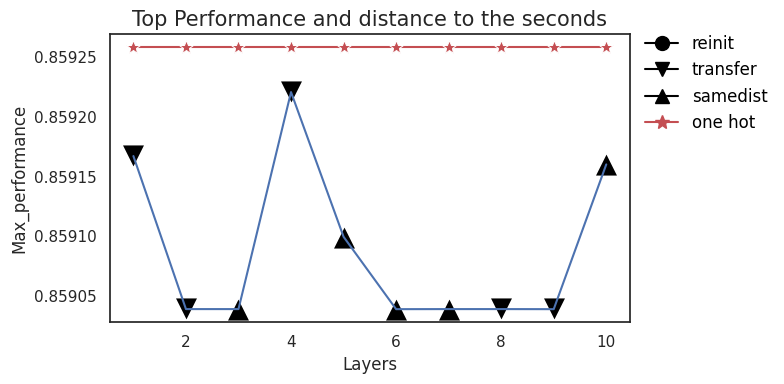

In [156]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Assuming layer_df and conditions are defined

# Create a figure and axis object
fig, axe = plt.subplots(figsize=(8, 4))

sns.set(style="white")

# Plot validation loss on the left y-axis
markers = [x for x in list(layer_df["second_min_loss_marker"]) if x is not np.nan]
sns.lineplot(x="layers", y="maxacc_value", data=layer_df, marker="*", markersize=10, color="r", ax=axe)

conditions = {"reinit": "o", "transfer": "v", "samedist": "^", "one hot": "*"}
inversed_conditions = {value: key for key, value in conditions.items()}

for i in range(10):
    y = [k for k in layer_df["second_max_acc_value"] if len(str(k)) > 3][i]
    marker = markers[i]
    label = inversed_conditions[marker]
    sns.scatterplot(x=[i + 1], y=[y], color="black", marker=marker, s=300, ax=axe, label=label)

sns.lineplot(x="layers", y="second_max_acc_value", data=layer_df, color="b", ax=axe)

# Update legend
legend_handles = [plt.Line2D([0], [0], marker=marker, color='black', markersize=10, label=label) if label != "one hot" 
                  else plt.Line2D([0], [0], marker=marker, color='r', markersize=10, label=label)
                  for label, marker in conditions.items()]
plt.legend(handles=legend_handles, frameon=False, fontsize=12, labelcolor="black", bbox_to_anchor=(1.0, 1.05))

plt.ylabel("Max_performance")
plt.xlabel("Layers")
plt.title("Top Performance and distance to the seconds", fontdict={'size':15})
output_dir = "/home/sxr280/BERTLocRNA/output/RNAlocalization_MultiPEFT/parnet/Figure"
os.makedirs(output_dir, exist_ok=True)  # Create the directory if it doesn't exist

# Save the plot as an image
output_path = os.path.join(output_dir, "Parnet_Layers_vs_performance.png")
plt.tight_layout()
plt.savefig(output_path, dpi = 300)
plt.show()
